# Softball Pitching Analysis: Data Problem

**Data:** 'South Dakota State_0466.csv' (one row per pitch)

Research Quesiton:
1. Which pitch characterisitcs are associated* with successful pitching outcomes?
2. Can we identify different ptching styles based on velocity, spin rate, and ball movement?

**First part (Q2):** working with clustering and create unsupervised Learning. \
**Second part (Q1):** reuseing the cleaned data and create supervised model to successfully pitching outcomes.

Start: Q2 \
End: Q1

Part 1 (Nathan's Work):
1. Data setup and Loading
2. Data Understanding
3. Data cleaning
4. Exploratory data analysis (EDA)
5. Feature engineering and feature groups
6. Dimensionality reduction (PCA per feature group)
7. Modeling: K-means (choosing k)
8. Interpreting the cluster choice
9. Validation
10. Pitcher analysis (answer q2)
11. Robustness check (HDBSCAN)
12. Limitation and summary

# 1. Data setup and Loading


In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [57]:
#upload excel file
from google.colab import files
uploaded = files.upload()

Saving South Dakota State_0466.csv to South Dakota State_0466 (1).csv


In [58]:
df = pd.read_csv('South Dakota State_0466.csv')

# 2. Data Understanding

In [59]:
df.head()

,PitchNo,Date,Time,PAofInning,PitchofPA,Pitcher,PitcherId,PitcherThrows,PitcherTeam,Batter,...,yt_EffectiveBattingSpeed,yt_ReleaseAccuracy,yt_ZoneAccuracy,yt_SeamLat,yt_SeamLong,yt_ReleaseDistance,Catcher,CatcherId,CatcherTeam,yt_AeroModel
0,1.0,3/14/2026,3:33:43 PM,1.0,1.0,Kynlee Bowlin,NaN,Right,Uta fall 25,Bria Riebel,...,NaN,high,high,NaN,NaN,36.916001,Mia Mcnulty,NaN,Uta fall 25,2022-11
1,2.0,3/14/2026,3:33:59 PM,1.0,2.0,Kynlee Bowlin,NaN,Right,Uta fall 25,Bria Riebel,...,39.074185,high,high,NaN,NaN,36.916001,Mia Mcnulty,NaN,Uta fall 25,2022-11
2,3.0,3/14/2026,3:34:33 PM,1.0,3.0,Kynlee Bowlin,NaN,Right,Uta fall 25,Bria Riebel,...,25.154829,high,high,NaN,NaN,36.916001,Mia Mcnulty,NaN,Uta fall 25,2022-11
3,4.0,3/14/2026,3:35:00 PM,2.0,1.0,Kynlee Bowlin,NaN,Right,Uta fall 25,Akayla Barnard,...,NaN,high,high,NaN,NaN,36.916001,Mia Mcnulty,NaN,Uta fall 25,2022-11
4,5.0,3/14/2026,3:35:20 PM,2.0,2.0,Kynlee Bowlin,NaN,Right,Uta fall 25,Akayla Barnard,...,NaN,high,high,NaN,NaN,36.916001,Mia Mcnulty,NaN,Uta fall 25,2022-11


In [60]:
df.shape

(259, 125)

In [61]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 259 entries, 0 to 258
Columns: 125 entries, PitchNo to yt_AeroModel
dtypes: float64(94), int64(4), object(27)
memory usage: 253.1+ KB


In [62]:
def print_unique(d, col):
  print(f'--| {col}: |--')
  print(d[col].value_counts(dropna=False))

In [63]:
def print_missing(d, top=25):
  missing = d.isna().mean().mul(100).round(1).sort_values(ascending=False)
  print(missing[missing > 0].head(top).to_string())

In [64]:
df.dtypes

,0
PitchNo,float64
Date,object
Time,object
PAofInning,float64
PitchofPA,float64
...,...
yt_ReleaseDistance,float64
Catcher,object
CatcherId,object
CatcherTeam,object


In [65]:
print(df.dtypes.value_counts())

float64    94
object     27
int64       4
Name: count, dtype: int64


In [66]:
#Missing values in the dataset
df.isnull().sum()

,0
PitchNo,1
Date,0
Time,0
PAofInning,1
PitchofPA,1
...,...
yt_ReleaseDistance,20
Catcher,1
CatcherId,128
CatcherTeam,1


In [67]:
#Missingness in % of rows missing, per column
print_missing(df, top=40)

PitcherSet                  100.0
AutoPitchType               100.0
Notes                       100.0
LastTrackedDistance         100.0
Level                       100.0
yt_SeamLat                  100.0
yt_SeamLong                 100.0
Note                        100.0
yt_SessionName              100.0
yt_FSRI                     100.0
Stadium                     100.0
League                      100.0
KorBB                        95.8
PositionAt110X               87.3
PositionAt110Y               87.3
PositionAt110Z               87.3
yt_HitSpinComponentZ         84.9
yt_HitBreakY                 84.9
yt_HitBreakT                 84.9
yt_HitSpinComponentX         84.9
yt_HitSpinComponentY         84.9
yt_HitSpinConfidence         84.9
yt_HitBreakX                 84.9
HitSpinRate                  84.9
HangTime                     82.6
ExitSpeed                    82.6
Angle                        82.6
Direction                    82.6
Distance                     82.6
yt_GroundLocat

<Axes: >

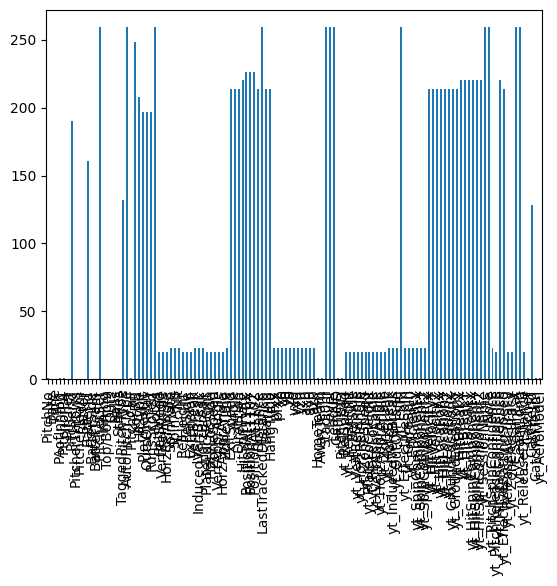

In [68]:
#create a graph with the missing vlaues greater than 20 missing in each columns
df.isnull().sum().plot(kind='bar')

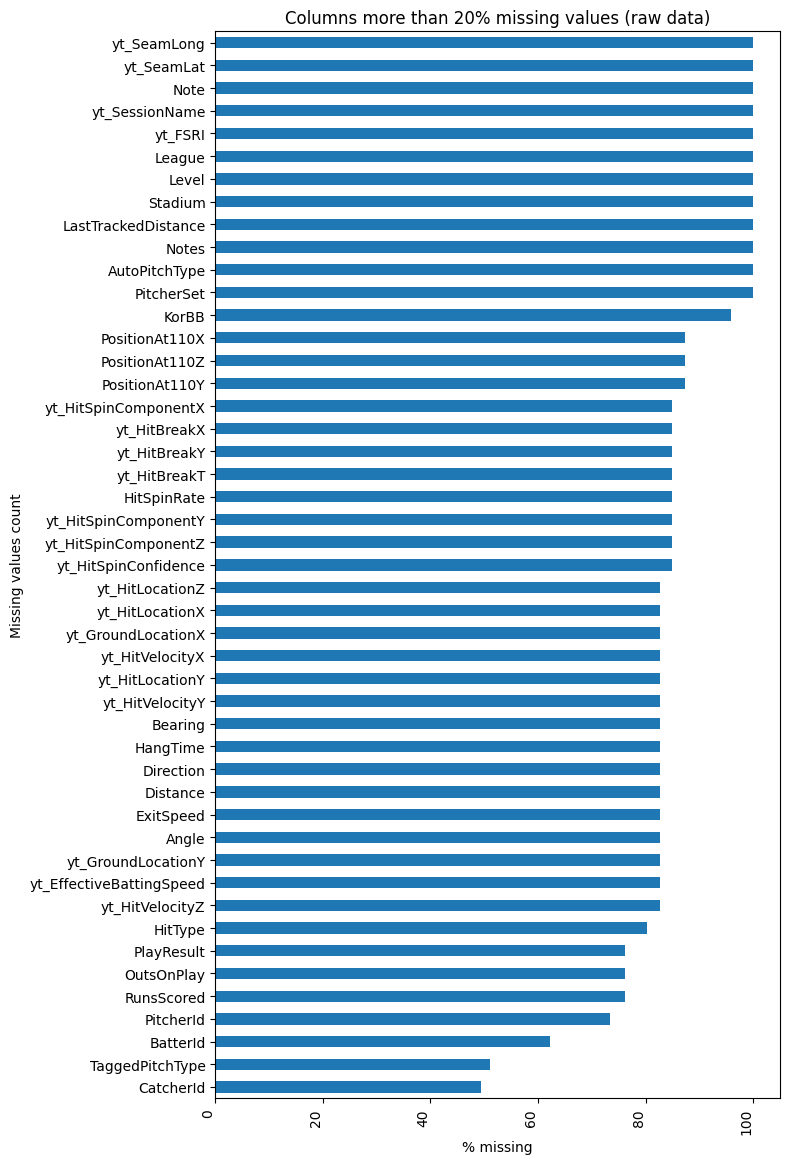

In [69]:
missing_values = df.isnull().mean().mul(100).round(1).sort_values()

plt.figure(figsize=(8, 6))
missing_values = missing_values[missing_values > 20]

missing_values.sort_values(ascending=True).plot(kind='barh', figsize=(8, max(3, 0.25 * len(missing_values))))

plt.title('Columns more than 20% missing values (raw data)')
plt.xlabel('% missing')
plt.ylabel('Missing values count')
plt.xticks(rotation=90, ha='right')
plt.tight_layout()
plt.show()

Above graph reading:
3 different likely reasons the data is missing and need to handle it:

**Drop columns:** 'PitcherSet', 'AutoPitchType' , 'Notes', because nothing was ever recorded for this features. \
**Ignore columns:** 'ExitSpeed', 'HitType', 'Distance', 'PLayResult', because it only exist when the ball was hit, can be excluded for answer q2 but keep for q1. \
**Missing reading:** 'RelSpeed', 'SpinRate', tracker did not record or failed to record, can drop those row or impute the rows.

In [70]:
#show numerical and categorical columns
df['PlayResult'].value_counts()

,count
PlayResult,
Out,30
Single,11
Walk,6
StrikeoutSwinging,5
Error,3
Double,3
FieldersChoice,3
HomeRun,1


In [71]:
df['PitchCall'].value_counts()

,count
PitchCall,
BallCalled,98
Foul,58
InPlay,52
StrikeCalled,36
StrikeSwinging,11
HitByPitch,3


In [72]:
#groupby with batterside and angular
df['PitchCall'].groupby(df['BatterSide']).value_counts()

BatterSide  PitchCall     
Left        BallCalled        18
            Foul              12
            InPlay            11
            StrikeCalled       8
            StrikeSwinging     4
Right       BallCalled        80
            Foul              46
            InPlay            41
            StrikeCalled      28
            StrikeSwinging     7
            HitByPitch         3
Name: count, dtype: int64

In [73]:
print(df['Batter'].value_counts())

Batter
Dee Mcclarity        24
Emma Vike            22
Ella  Berlange       17
Kaylee Schweitzer    15
Alli Boyle           15
Marley Neises        15
Emma Christensen     14
Mia Mcnulty          14
Bria Riebel          13
Kaitlyn Sailor       12
Kelsey Creech        12
Quinn Marnocha       12
Akayla Barnard       11
Amanda Vacanti       10
Valeria Feeney       10
Talia Maldonado       9
Peyton Holland        9
Abby Gentry           7
Tayler Baker          7
Cameron Cooper        6
Taylor Minor          5
Name: count, dtype: int64


In [74]:
print_unique(df, "PitchCall")

--| PitchCall: |--
PitchCall
BallCalled        98
Foul              58
InPlay            52
StrikeCalled      36
StrikeSwinging    11
HitByPitch         3
NaN                1
Name: count, dtype: int64


In [75]:
print_unique(df, "PitcherTeam")

--| PitcherTeam: |--
PitcherTeam
South dakota state [sou03:2025]    131
Uta fall 25                        128
Name: count, dtype: int64


In [76]:
print_unique(df, "TaggedPitchType")

--| TaggedPitchType: |--
TaggedPitchType
NaN       132
Curve      47
Screw      37
Rise       30
Change     10
Fast        2
RIse        1
Name: count, dtype: int64


# 3. Data Cleaning

'clean()' function that fixes everything we found in stage 2.
- Can reuse that function on any new file from future UTA softball dataset, and future project.

Steps in 'clean()' function:
- Drop rows with no 'GameID' (blank or partially blank rows);
- Drop all columns with zero information (since its 100% empty has no information);
- Drop all 'yt_' columns (its like a second tracking system of the measurements already in the columns);
- Drop ID-type columns (it's not an identifying feature, it's just noise);
- Standardize pitcher names (example 'Grace  Proctor', has extra space between her name so standardize to show same player);
- Standardize Team name ('South dakota state [sou03:2025]', rename it to SDU, also 'uta fall 25', will be UTA);
- Pitch-type rename ('RIse' would  become 'Rise');
- 'Tilt' to time (change to clock time since the model would need actual numbers);
- Suggestion: 'assert' unique 'PitchUUID' to check for no duplicate pitch at the clustering stage.

In [77]:
ID_COLS = ["KorrBB", "PitchNo", "PitchUUID", "BatterId", "PitcherId", "CatcherId"]

def team_label(x):
  if not isinstance(x, str):
    return x
  t = x.lower()
  if t.statswith("south dakota"):
    return "SDSU"
  if t.startswith("uta"):
    return "UTA"
  return x

In [78]:
def team_label(x):
  if not isinstance(x, str):
    return x
  t = x.lower()
  if t.startswith("south dakota"):
    return "SDSU"
  if t.startswith("uta"):
    return "UTA"
  return x

def clean(d):
  d = d[d["GameID"].notna()].copy()                          # blank rows
  assert d["PitchUUID"].is_unique, "Duplicate pitches found" # integrity check
  d = d.dropna(axis=1, how="all")                            # empty columns
  d = d.filter(regex="^(?!yt_)")                             # second tracking system
  d = d.drop(columns=[c for c in ID_COLS if c in d.columns])

  for c in ["Pitcher", "Batter", "Catcher"]:                 # names: whitespace + casing
    d[c] = d[c].str.split().str.join(" ").str.title()
  for c in ["PitcherTeam", "BatterTeam", "CatcherTeam"]:     # team names/labels
    d[c] = d[c].map(team_label)
  d["TaggedPitchType"] = d["TaggedPitchType"].str.title()    # RIse -> rise

  # tilt: clock time -> degrees (12:00 = 0 deg, 30 deg per hour, 0.5 deg per minute)
  t = pd.to_datetime(d["Tilt"], format="%H:%M", errors="coerce")
  d["Tilt"] = (t.dt.hour * 30 + t.dt.minute * 0.5) % 360
  return d.reset_index(drop=True)

df_clean = clean(df)
print("Before:", df.shape, "| After:", df_clean.shape)

Before: (259, 125) | After: (258, 66)


In [79]:
print_unique(df_clean, "Pitcher")
print_unique(df_clean, "PitcherTeam")

--| Pitcher: |--
Pitcher
Maddie Furniss    81
Grace Proctor     54
Tayler Baker      51
Kynlee Bowlin     46
Keira Carrillo    18
Bella Macmahon     8
Name: count, dtype: int64
--| PitcherTeam: |--
PitcherTeam
SDSU    131
UTA     127
Name: count, dtype: int64


4. Exploratory data analysis (EDA)

Summarize and visualize the pitch measuremnts before modeling. \
why: EDA tells us whether clustering is even plausible (do pitchers differ?), whether features are on very different scale (which they are), and whether features are redundant (some are redundant, which will help in PCA step)

In [80]:
#start with descriptive statistics for each pitcher (using 'RelSpeed' and 'SpinRate')
def iqr(x):
  return x.quantile(0.75) - x.quantile(0.25)

pitch_stats = (
    df_clean.dropna(subset=["RelSpeed", "SpinRate"])
    .groupby("Pitcher")["RelSpeed"]
    .agg(Count="count", Mean="mean", Std="std", Median="median" , Min="min", Max="max", IQR=iqr)
    .round(2)
)
print("Release Speed (mph) Stats per Pitcher:")
print(pitch_stats)

Release Speed (mph) Stats per Pitcher:
                Count   Mean   Std  Median    Min    Max   IQR
Pitcher                                                       
Bella Macmahon      7  64.66  3.55   66.82  59.39  67.06  4.18
Grace Proctor      51  62.65  1.68   62.83  57.20  64.47  1.57
Keira Carrillo     17  66.67  2.48   66.99  58.28  70.32  1.45
Kynlee Bowlin      40  57.73  5.13   60.06  47.60  62.06  4.61
Maddie Furniss     72  68.53  1.00   68.54  65.68  71.20  1.21
Tayler Baker       49  65.22  4.37   66.75  51.89  68.70  1.85


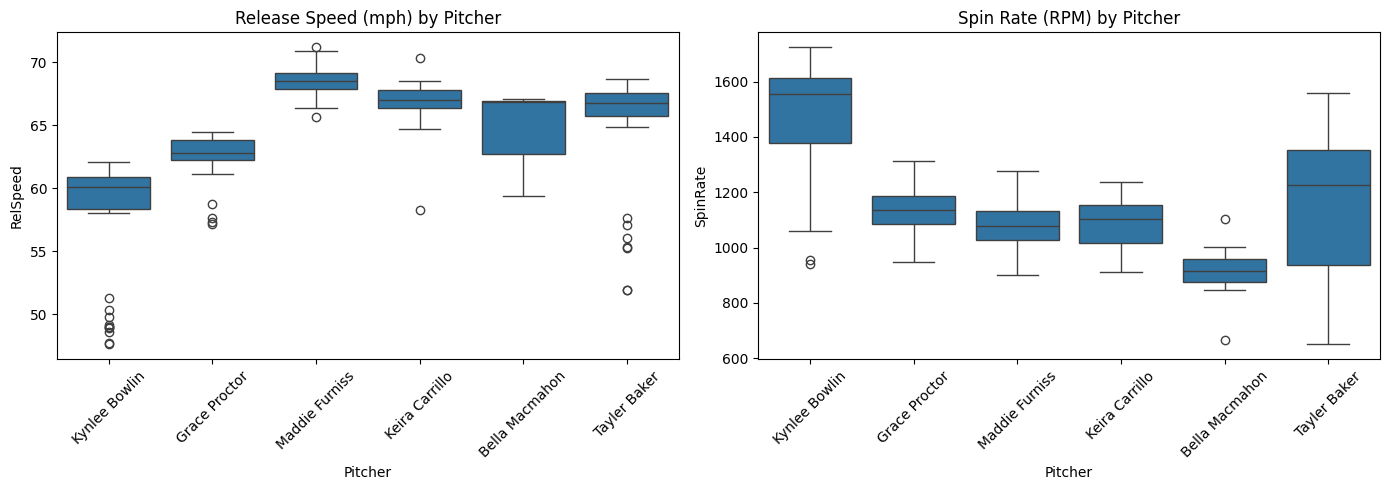

In [81]:
#graph of release speed and spin rate for each player

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df_clean, x="Pitcher", y="RelSpeed", ax=axes[0])
axes[0].set_title("Release Speed (mph) by Pitcher")
axes[0].tick_params(axis='x', rotation=45)
sns.boxplot(data=df_clean, x="Pitcher", y="SpinRate", ax=axes[1])
axes[1].set_title("Spin Rate (RPM) by Pitcher")
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

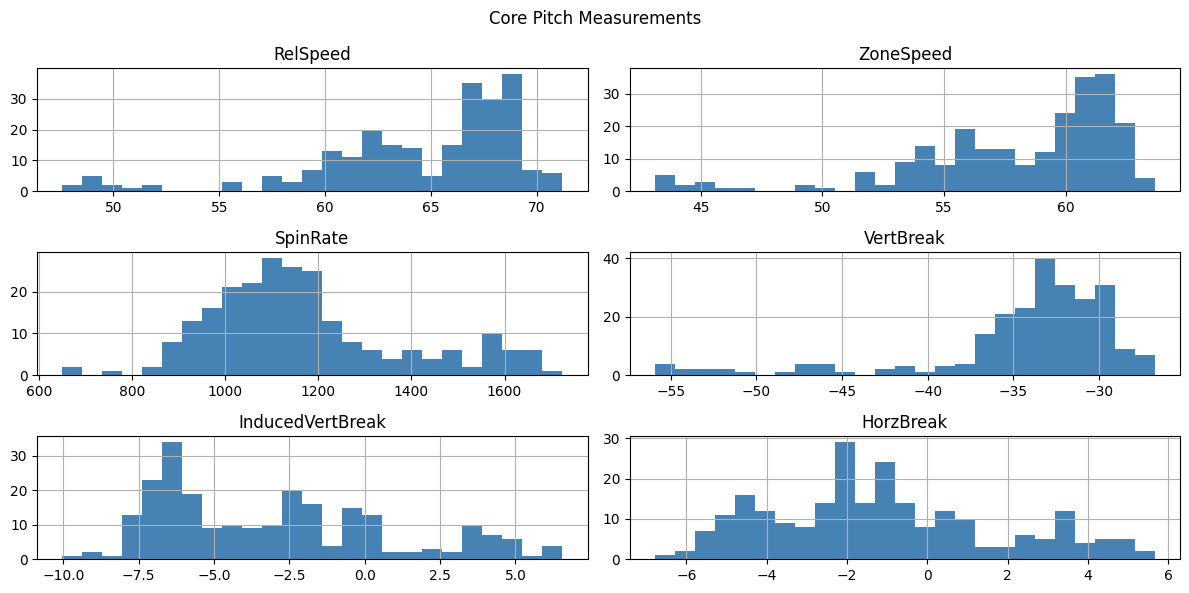

In [82]:
#Distributions of the core measuremnts
core_view = ["RelSpeed", "ZoneSpeed", "SpinRate", "VertBreak", "InducedVertBreak", "HorzBreak"]
df_clean[core_view].hist(bins=25, figsize=(12, 6), color= "steelblue")
plt.suptitle("Core Pitch Measurements")
plt.tight_layout()
plt.show()

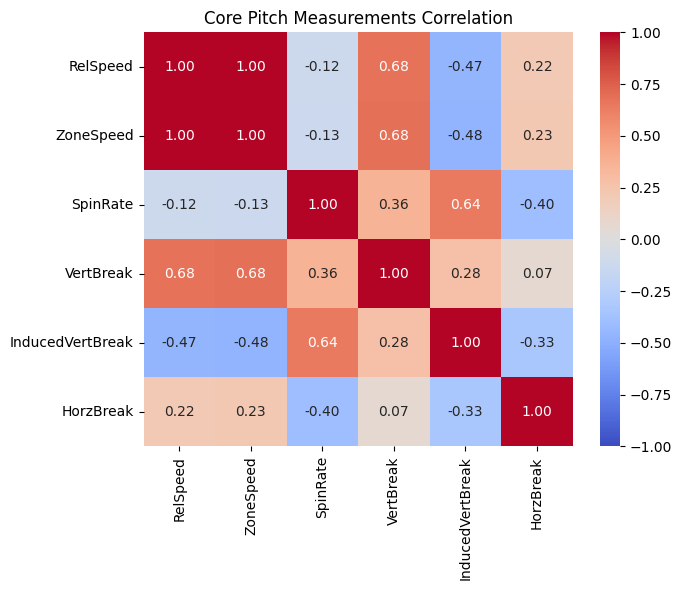

In [83]:
#Correlation among the core measurements (check any redundancy in measuremnts)
plt.figure(figsize=(7, 6))
sns.heatmap(df_clean[core_view].corr(), annot=True, fmt=".2f" , cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Core Pitch Measurements Correlation")
plt.tight_layout()
plt.show()

The features are measured in different units (mph, rpm, inches), so raw distances would dominated by whichever feature has bigger numbers (which is spin rate in thousands vs. speed in the sixties). \
Several features are highly correlated ('RelSpeed' and 'ZoneSpeed', have same pitch measured at release and at the plate.)
- Those two facts directly justify standardization and PCA in the next stages.

# 5. Feature Engineering and Feature groups

1. Encode cicular variables:
'SpinAxis' is an angle in degrees, so 359 degrees and 1 degree are almost the same direction, but numerically they look 358 apart. The fix is to replace the angle with two columns, 'sin(angle)' and 'cos(angle)', which place it on a circle. 'Tilt' is the same quantity as 'SpinAxis ', written as clock time (per the data dictinary), so we keep only SpinAxis to avoid duplicatin information.

2. Feature groups: with 259 rows ad dozens of numeric columns, throwing everything into one model invites overfitting and the curse of dimensionality. Grouping related measurements lets us compress each group separately (Step 6), which keeps the result interpretable ("the Movement component", not "component 17").

3. Choosing groups for Q2: the question takes in account the velocity, spin rate, and ball movement, so those three groups are the clustering features. Release mechancis, plate location, approach angle, raw phyiscs, and batted-ball (flight) columns are kept in the dictionary for reference and future checks, but are not used to define the "style":
- Batted-ball columns are about what the batter did, and are 80%+ missing.
- Plate location is about where the pitch ended up, which is mostly an outcome (ball or strike) rather than how it was thrown.

(Groups are defined by column name, not by column position number.)

In [84]:
df_FE = df_clean.copy()

In [85]:
#Circular encoding of the spin axis
theta = np.deg2rad(df_FE["SpinAxis"])
df_FE["sin(SpinAxis)"] = np.sin(theta)
df_FE["cos(SpinAxis)"] = np.cos(theta)
df_FE = df_FE.drop(columns=["SpinAxis"])

In [87]:
feature_groups = {
    "Velocity": ["RelSpeed", "ZoneSpeed"],
    "Spin": ["SpinRate", "sin(SpinAxis)", "cos(SpinAxis)"],
    "Movement": ["VertBreak", "InducedVertBreak", "HorzBreak", "pfxx", "pfxz"],
    # Remainging features are important for the Q1, but not important for Q2
    "Release": ["VertRelAngle", "HorzRelAngle", "RelHeight", "RelSide", "Extension"],
    "Approach": ["VertApprAngle", "HorzApprAngle", "ZoneTime"],
    "Location": ["PlateLocHeight", "PlateLocSide"],
    "Trajectory": ["x0", "y0", "z0", "vx0", "vy0", "vz0", "ax0", "ay0", "az0"],
    }

Q2_groups = ["Velocity", "Spin", "Movement"]
Q1_groups = ["Velocity", "Spin", "Movement", "Release", "Approach", "Location", "Trajectory"]

q2_groups = {g: [c for c in feature_groups[g] if c in df_FE.columns] for g in Q2_groups}
core_cols = [c for cols in q2_groups.values() for c in cols]
print({g: cols for g, cols in q2_groups.items()})

{'Velocity': ['RelSpeed', 'ZoneSpeed'], 'Spin': ['SpinRate', 'sin(SpinAxis)', 'cos(SpinAxis)'], 'Movement': ['VertBreak', 'InducedVertBreak', 'HorzBreak', 'pfxx', 'pfxz']}


## Handle Missing sensor readings:
- About 8 to 9% of pitches have no tracker data, also those rows are missing all the physics data, not a single value is there.
- Drop those missing more than 50% of the data, and fill the few remaining gaps with median inside PCA processing. (Then why not just fill all with median rather then dropping them, But filling all eith median is just saying ther is average pitch in the game, when that never really happened, and that would pull all the cluster values closer to the center.)

In [88]:
missing_share = df_FE[core_cols].isna().mean(axis=1)
df_model = df_FE[missing_share <=0.5].copy()

print(f"Pitches before: {len(df_FE)} | kept for modeling: {len(df_model)} | dropped (no tracker data): {len(df_FE)- len(df_model)}")
print("\nRemaining missing values is core columns:")
print(df_model[core_cols].isna().sum()[lambda s: s > 0])

Pitches before: 258 | kept for modeling: 236 | dropped (no tracker data): 22

Remaining missing values is core columns:
Series([], dtype: int64)


^ What does the result mean? It means every missing sensor value was inside those 22 dropped pitches, and none partial gaps survived.
- 22 pitches had no tracker data and were excluded. No missing values reamined in the clustering features, so imputation was not needed.

# 6. Dimensionality reduction (PCA per feature group)

Inside each feature group:
1. Fill leftover gaps with the median
2. Standardize (Mean 0, standard deviation 1)
3. Run PCA and kepp the fewest components that explain at least 90% of the variance.

Put in report why each step needed:
- Median imputation: simple and robust to outliers
- Standardization: K-means use distances, and a feature measured in thousands (rpm) would otherwise drown out one measured in tens (mps).
- PCA: rotates correlated features into uncorrelated principle components ordered by how much variance they capture. Keeping 90% removes redundancy and noise while preserving nearly all the information.
- Per group: each component stays interpretable as "a Velocity component" or "a Movement component".

In [90]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import adjusted_rand_score

In [106]:
def group_pca(frame, groups, var_target=0.90):
  scores, models, loadings, summary = [], {}, {}, []
  for name, cols in groups.items():
    prep = Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("scale", StandardScaler())])
    Z = prep.fit_transform(frame[cols])
    pca = PCA().fit(Z)
    cum = np.cumsum(pca.explained_variance_ratio_)
    n = int(np.argmax(cum >= var_target)) + 1
    pcs = pd.DataFrame(pca.transform(Z)[:, :n],
                       columns=[f"{name}_PC{i+1}" for i in range(n)],
                       index=frame.index)
    scores.append(pcs)
    models[name] = pca
    loadings[name] = pd.DataFrame(pca.components_[:n].T,
                                  index=cols,
                                  columns=[f"P{i+1}" for i in range(n)]).round(3)
    summary.append({"Group": name, "Features": len(cols),
                    "PCs kept": n, "Variance explained": round(cum[n-1], 3)})
  return pd.concat(scores, axis=1), models, loadings, pd.DataFrame(summary)

X, pca_models, loadings, pca_summary = group_pca(df_model, q2_groups)
print(pca_summary.to_string(index=False))
print("\nClustering matrix X:", X.shape)

   Group  Features  PCs kept  Variance explained
Velocity         2         1               0.999
    Spin         3         2               0.903
Movement         5         3               0.992

Clustering matrix X: (236, 6)


In [107]:
#loadings: which originial features drive each components?
for g, ld in loadings.items():
    print(f"---- {g} loadings -----")
    print(ld, "\n")

---- Velocity loadings -----
              P1
RelSpeed   0.707
ZoneSpeed  0.707 

---- Spin loadings -----
                  P1     P2
SpinRate      -0.599 -0.467
sin(SpinAxis) -0.497  0.854
cos(SpinAxis)  0.628  0.230 

---- Movement loadings -----
                     P1     P2     P3
VertBreak         0.143  0.567  0.810
InducedVertBreak  0.516  0.337 -0.353
HorzBreak        -0.452  0.495 -0.285
pfxx              0.493 -0.437  0.200
pfxz              0.515  0.359 -0.313 



# 7. modeling with k-means (choosing K)

K-mean, places k centers, assign each pitch to the nearest center, moves the centers, and repeats until stabel. Since we have no Target columns for this question, this is the best option.

Elbow method and silhouetter score (-1 to 1):
we use both and also ask whether the cluster makes sense in the softball game.

In [108]:
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
  km = KMeans(n_clusters=k, n_init=10, random_state=42). fit(X)
  inertia.append(km.inertia_)
  sil.append(silhouette_score(X, km.labels_))

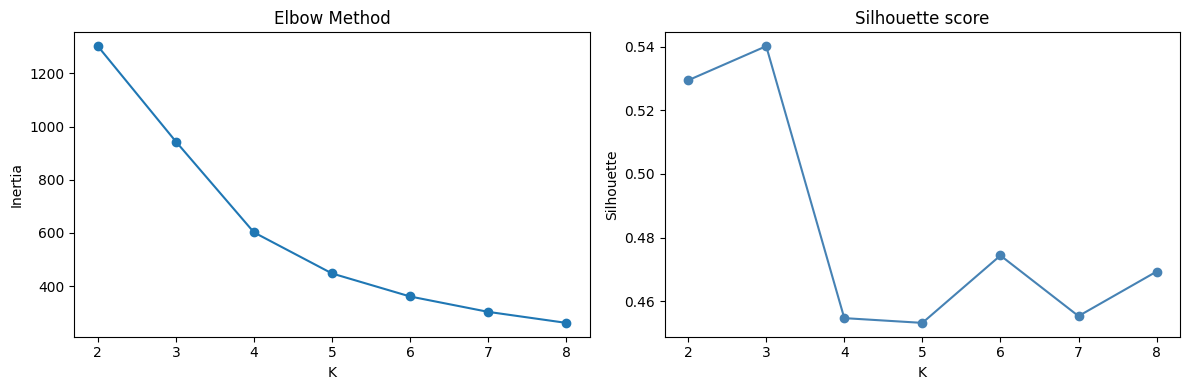

 K  Inertia  Silhouette
 2   1302.5       0.529
 3    943.7       0.540
 4    602.2       0.455
 5    447.8       0.453
 6    361.2       0.474
 7    303.4       0.455
 8    262.0       0.469
K with the best silhouette: 3


In [111]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inertia, marker="o")
axes[0].set(title="Elbow Method", xlabel="K", ylabel="Inertia")
axes[1].plot(list(ks), sil, marker="o", color="steelblue")
axes[1].set(title="Silhouette score", xlabel="K", ylabel="Silhouette")
plt.tight_layout()
plt.show()

print(pd.DataFrame({"K": list(ks), "Inertia": np.round(inertia, 1), "Silhouette": np.round(sil, 3)}).to_string(index=False))
print("K with the best silhouette:", list(ks)[int(np.argmax(sil))])

In [114]:
#Choosing K from the plots above, 3 is the best choice.
K = 3
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
labels = pd.Series(kmeans.fit_predict(X), index =X.index, name="Cluster")
df_model["Cluster"] = labels

print("Cluster sizes:")
print(labels.value_counts().sort_index())
print(f"\nSilhouette score (k={K}): {silhouette_score(X, labels):.3f}")

Cluster sizes:
Cluster
0     33
1    186
2     17
Name: count, dtype: int64

Silhouette score (k=3): 0.540


# Step 8: Interpreting the clusters

Turning abstract cluster numbers into baseball meaning.
- Cluster is only useful if a coach can understand it, like "68mph with 1100 rpm" means somehting but the pc1 = 0.8 means nothing to the coaches.
- Create the profile table and then name the clusters, since the numbers can change just inspect the profiles first and wait for the naming the cluster.


In [116]:
profile_cols = ["RelSpeed", "ZoneSpeed", "SpinRate", "VertBreak", "InducedVertBreak", "HorzBreak"]
profile = df_model.groupby("Cluster")[profile_cols].mean().round(2)
profile.insert(0, "Pitches", df_model["Cluster"].value_counts().sort_index())
print("----- Cluster Profiles (Mean of each measuremnts) ----")
print(profile)

----- Cluster Profiles (Mean of each measuremnts) ----
         Pitches  RelSpeed  ZoneSpeed  SpinRate  VertBreak  InducedVertBreak  \
Cluster                                                                        
0             33     61.08      54.75   1552.43     -30.27              3.97   
1            186     66.28      59.62   1115.86     -33.62             -4.40   
2             17     51.56      46.23   1027.57     -50.69             -1.84   

         HorzBreak  
Cluster             
0            -4.62  
1            -0.27  
2            -4.31  


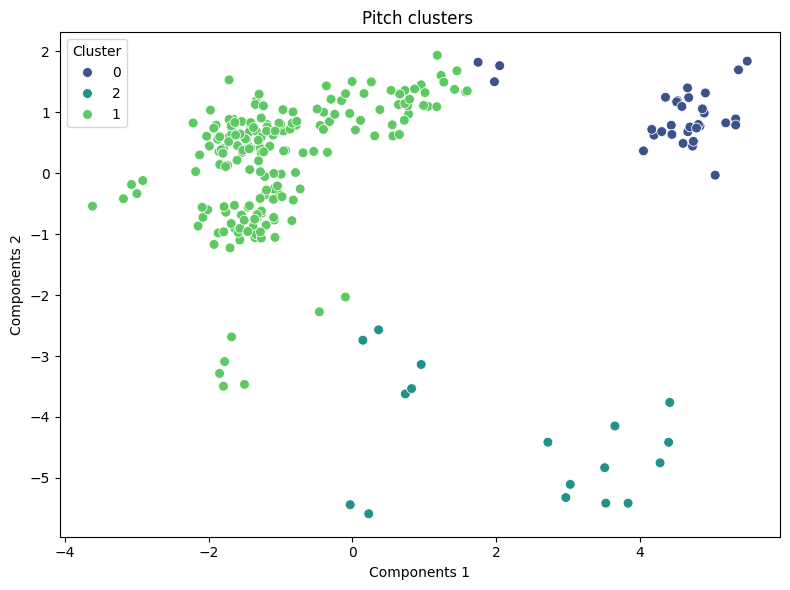

In [117]:
#graph of the clusters (PCA used here only for visual)
xy = PCA(n_components=2, random_state=42).fit_transform(X)
plt.figure(figsize=(8,6))
sns.scatterplot(x=xy[:,0], y=xy[:, 1], hue=labels.astype(str), palette="viridis", s=50)
plt.xlabel("Components 1")
plt.ylabel("Components 2")
plt.title("Pitch clusters ")
plt.tight_layout()
plt.show()

In [125]:
Cluster_names = {0: "Power / high Speed", 1: "Offspeed / slow", 2: "High-spin Movement"}

# 9. Validation

- Silhouette score: internal measure od cluster separation
- Stability: Rerun kmean with different seeds.
- External check agianst pitch tags: half the pitches have recorded 'TaggedPitchType' (Curve, Screw, Rise, Change, Fast). We did not use the tags to build the clusters, so agreement with them is independent evidence. The Adjusted Rand Index (ARI) measures agreement between two labeling: 1= identical, 0 = no better than chance.
- Picher identity? - Cluster line up with who threw the pitch, the styles may really be individual pitchers differneces. That is not wrong but we need to know.

In [119]:
#stability across random seeds
stab = [adjusted_rand_score(labels, KMeans(n_clusters=K, n_init=10, random_state=s).fit_predict(X))
         for s in range(10)]
print(f"Stability (ARI vs. the chosen solution, 10 seeds): mean={np.mean(stab):.3f}, min={np.min(stab):.3f}")

Stability (ARI vs. the chosen solution, 10 seeds): mean=1.000, min=1.000


In [120]:
#external check against the recorde pitch tags
tags = df_model["TaggedPitchType"]
tagged = tags.notna()
print(f"Tagged pitches available: {tagged.sum()} of {len(df_model)}")
print(pd.crosstab(labels[tagged], tags[tagged], margins=True))
print(f"\nARI (Cluster vs. tags): {adjusted_rand_score(tags[tagged], labels[tagged]):.3f}")

Tagged pitches available: 111 of 236
TaggedPitchType  Change  Curve  Fast  Rise  Screw  All
Cluster                                               
0                     0      1     2     5     22   30
1                     0     38     0    24      9   71
2                    10      0     0     0      0   10
All                  10     39     2    29     31  111

ARI (Cluster vs. tags): 0.330


In [122]:
# Are sluster just pitcher identity?
print(f"ARI (Clusters vs. Pitcher): {adjusted_rand_score(df_model['Pitcher'], labels):.3f}")

ARI (Clusters vs. Pitcher): 0.176


^Results above:  Cluster membership was only weakly related to pitcher identity (ARI=0.176), indicating the clusters capture pitch characteristic shared across pitchers rather than simply sparating individual pitchers.

Techincally, ARI hides how pitchers differ.

# 10. Pitchers Analysis (arsenals)

With only 6 pitchers, clustering the pitchers direclt wwould be too thin to trust. So we cluster the pitches, now we would describe each pitchers by the mix of clusters they throw. A pitchers arsenal is the percentage of their pitches in each clucter.

- This would turn the pitch level clusters into pitcher level style: a pitcher who throws mostly one cluster has a different style from one who spreads across several.

In [129]:
arsenal_counts = pd.crosstab(df_model["Pitcher"], df_model["Cluster"])
arsenal_pct = (pd.crosstab(df_model["Pitcher"], df_model["Cluster"], normalize="index")* 100).round(1)
arsenal_pct = arsenal_pct.rename(columns=Cluster_names)
arsenal_pct["Total_Pitches"] = arsenal_counts.sum(axis=1)

print("---- Pitcher Arsenal Distribuiton (%) -----")
print(arsenal_pct)

---- Pitcher Arsenal Distribuiton (%) -----
Cluster         Power / high Speed  Offspeed / slow  High-spin Movement  \
Pitcher                                                                   
Bella Macmahon                 0.0            100.0                 0.0   
Grace Proctor                  0.0            100.0                 0.0   
Keira Carrillo                 5.9             94.1                 0.0   
Kynlee Bowlin                 75.0              0.0                25.0   
Maddie Furniss                 0.0            100.0                 0.0   
Tayler Baker                   4.1             81.6                14.3   

Cluster         Total_Pitches  
Pitcher                        
Bella Macmahon              7  
Grace Proctor              51  
Keira Carrillo             17  
Kynlee Bowlin              40  
Maddie Furniss             72  
Tayler Baker               49  


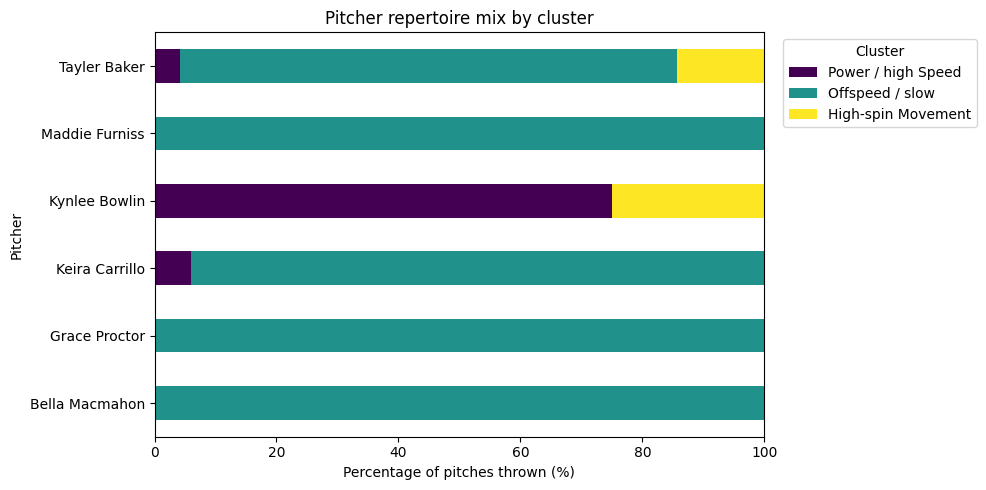

In [135]:
ax = arsenal_pct.drop(columns=["Total_Pitches"]).plot(
    kind="barh", stacked=True, figsize=(10, 5), colormap="viridis")
ax.set_xlim(0, 100)
ax.set_xlabel("Percentage of pitches thrown (%)")
ax.set_title("Pitcher repertoire mix by cluster")
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# 11. Robustness check (HDBSCAN)

K-means forces every pitch into exactly K round-ish clusters. HDBSCAN is density-based: it finds clusters of any shape, chooses the number of cluster itself, and labels unusual pitches as noise(-1).
- Its a comlpetely different algorithm that finds a similar structure, our conclusion would be more trust worthy. This would be a check not the main result.

In [136]:
from sklearn.cluster import HDBSCAN

In [140]:
hdb = HDBSCAN(min_cluster_size=8)
hdb_labels = pd.Series(hdb.fit_predict(X), index=X.index, name="HDBSCAN")

print("HBSCAN cluster sizes (-1 = noise):")
print(hdb_labels.value_counts().sort_index())

mask = hdb_labels != -1
if mask.sum() > 1 and hdb_labels[mask].nunique() > 1:
  print(f"\nARI (K-means vs. HDBSCAN, non-noise pitches): {adjusted_rand_score(labels[mask], hdb_labels[mask]):.3f}")

HBSCAN cluster sizes (-1 = noise):
HDBSCAN
-1      9
 0     30
 1    187
 2     10
Name: count, dtype: int64

ARI (K-means vs. HDBSCAN, non-noise pitches): 0.910


# 12. Limitation and Summary

Limitation:
- Small Sample size: a few hundrede pitches and only six pitcher. Results are exploratory not definitive.
- Pitches are not independant: many comes from the same pitcher in the same game, so clusters can reflect individual pitchers
- Clustering is modeling choice, not truth: Different K, features, or algorithms can give different groups. We justified K with elbow and silhouette and checked stability and a second algorithm.
- Missing tracker data: Pitches with no readings were excluded, which assumes they are not systematically different.
- Tag are incomplete: About half the pitches have no recorded type, so the external check covers only part of the data.

Summary:
Cleaned the pitch data, encoded circular variables, compressed velocity, spin, and movement with PCA (keeping 90% of the variance in each group), and clustered the pitches that have complete tracker data with K-means. We chose K using the elbow method and silhouette score, confired stability across random seeds, compared the clusters with the recorded pitch tags, and summarized each pitcher's style as the mix of clusters they throw.

## What can be reused for Q1 from Q2 code?
-'df_clean()' and 'df_model' with 'cluster' for supervised analysis. Q1 the target column will be 'PitchCall', and the 'cluster' label can be tested as a feature ('does style matter for success?").



---
# Q1: Which Pitch characteristics are associated with successful pitching outcomes?


Supervised Learning Problem: The known outcome 'PitchCall', we ask which measured features help predict it.

## 1. Operationalizing 'Success'
Success is not a column; we will define it using 'PitchCall'


**A(strict):** Success = 1 (Called strike, wingingstrike), Success = 0 (ball, hit-by-pitch), Left out (foul, inplay)

**B(Normal):** Success = 1 (Called strike, swinging strike, foul), Success = 0 (ball, hit-by-pitch), Left Out (in-play)

Use B, since foul is a pitcher-favorable result (couts as strike when there are fewer than two strikes), and including it gives a more balanced and larger sample.

'In-play' is excluded because, whether a batted ball becomes an out or hit dpends on the defense and the ball's flight, not only on the pitch. Count that as the limitation; the hits mean we lose pitches.


Feature A: Pitch Characteristics: speed, spin, movement, release. This is what the question literally asks about.
Feature B: Characteristics + plate llocation: Location almost directlt decides ball vs. strike, so it will dominate. Comparing A and B shows how much the intrinsic pitch qualities matter once location is accounted for.



# 2. Target Variable

'PitchCall'